# Performance analysis — all personas with completed trial jobs

Heatmaps retained. Eight personas plus off; include all available results from their completed Astra trial jobs. Off/148/155/089/001/127 have three trials; 003/004/046 have one. The cancelled initial run and personas without any completed trial are excluded. Repairs replace endpoints within a trial and are not extra repeats.

In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Markdown, Image, Code
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
sys.path.insert(0, str(ROOT/'Experiment/shared'))
from analysis_utils import ARMS, SOURCES, FAMILIES, NAMES, label, cell, markdown_table
sys.path.insert(0,str(ROOT/'Experiment/02_performance_and_fields/code'))
import analyze_all_available as analysis
import plot_pairwise_performance as plotting
import pairwise_performance


## Frozen data and aggregation
Use `analysis.collect()` only to intentionally refresh saved campaign results. Available endpoints prefer an evaluable repaired outcome, with fallback to an evaluable original when repair failed. This is not selection of the highest score. Missing submissions score zero; infrastructure failures remain missing. Average observed repeats within task before averaging tasks. Study-cluster CIs condition on available trials and do not quantify run variation for one-trial personas.

In [2]:
snapshot=json.loads((analysis.DATA/'snapshot.json').read_text())
summary=json.loads((analysis.DATA/"summary.json").read_text())
analysis.report(summary)
print('Frozen snapshot SHA256:',summary['snapshot_sha256'])
print('Personas:',summary['arms'])

Frozen snapshot SHA256: 32653a253228c0a71f10f7b691c985fd7d9e36aadcc05880bce5769e6ce3569f
Personas: ['persona_off', 'candidate_148', 'candidate_155', 'candidate_089', 'candidate_001', 'candidate_127', 'candidate_003', 'candidate_004', 'candidate_046']


In [3]:
display(Markdown(markdown_table(['Persona','Trials with scores','Evaluable episodes','Tasks','Recorded unscored'],[[label(a),','.join(map(str,v['trials_with_scores'])) or 'none',v['evaluable'],v['tasks'],v['recorded_slots']-v['evaluable']] for a,v in summary['coverage'].items()])))

| Persona | Trials with scores | Evaluable episodes | Tasks | Recorded unscored |
|---|---|---|---|---|
| 001 | 1,2,3 | 595 | 200 | 5 |
| 003 | 1 | 123 | 123 | 77 |
| 004 | 1 | 177 | 177 | 23 |
| 026 | none | 0 | 0 | 0 |
| 046 | 1 | 185 | 185 | 15 |
| 089 | 1,2,3 | 597 | 200 | 3 |
| 127 | 1,2,3 | 592 | 200 | 8 |
| 148 | 1,2,3 | 572 | 200 | 28 |
| 155 | 1,2,3 | 556 | 199 | 44 |
| 224 | none | 0 | 0 | 0 |
| 262 | none | 0 | 0 | 0 |
| Off | 1,2,3 | 576 | 199 | 24 |

## Available performance tables
All available scored outcomes from eligible trials contribute. Absolute ASI values span historical judge versions and are descriptive. Super-families mix native metrics and source compositions. Each cell gives mean [95% CI], distinct tasks and evaluable trial episodes.

In [4]:
for field,groups in [('source',SOURCES),('family',FAMILIES)]:
    display(Markdown('### '+field))
    display(Markdown(markdown_table(['Persona',*[NAMES[g] for g in groups]],[[label(a),*[analysis.cell(summary['absolute']['available'][a][field][g]) for g in groups]] for a in summary['arms']])))

### source

| Persona | ASI-Bench | BixBench | DiscoveryBench | EXP-Bench | SciConvBench |
|---|---|---|---|---|---|
| Off | 47.86 [37.53, 58.55]; n=39, e=100 | 30.83 [8.13, 54.35]; n=40, e=119 | 13.14 [6.06, 16.73]; n=40, e=117 | 43.95 [36.66, 51.27]; n=40, e=120 | 85.00 [74.17, 94.17]; n=40, e=120 |
| 148 | 49.56 [38.97, 60.59]; n=40, e=100 | 30.00 [7.32, 53.85]; n=40, e=118 | 13.66 [9.36, 15.66]; n=40, e=114 | 44.04 [37.12, 51.08]; n=40, e=120 | 85.83 [75.83, 94.17]; n=40, e=120 |
| 155 | 52.57 [41.47, 63.55]; n=39, e=99 | 30.83 [8.13, 54.35]; n=40, e=119 | 15.27 [7.74, 21.74]; n=40, e=111 | 43.05 [35.83, 50.29]; n=40, e=107 | 85.00 [75.83, 92.50]; n=40, e=120 |
| 089 | 50.16 [39.84, 60.75]; n=40, e=118 | 30.83 [8.13, 54.35]; n=40, e=120 | 14.79 [7.96, 20.39]; n=40, e=119 | 45.68 [37.52, 53.93]; n=40, e=120 | 87.50 [77.50, 95.00]; n=40, e=120 |
| 001 | 51.85 [41.16, 62.85]; n=40, e=117 | 30.83 [8.13, 54.35]; n=40, e=120 | 14.50 [7.09, 22.86]; n=40, e=118 | 44.61 [37.23, 52.25]; n=40, e=120 | 90.00 [80.83, 97.50]; n=40, e=120 |
| 127 | 51.30 [40.58, 62.33]; n=40, e=114 | 30.83 [8.13, 54.35]; n=40, e=119 | 14.00 [8.63, 20.09]; n=40, e=119 | 44.10 [36.64, 51.74]; n=40, e=120 | 89.17 [80.00, 96.67]; n=40, e=120 |
| 003 | 50.62 [28.47, 73.48]; n=11, e=11 | 31.43 [6.90, 56.76]; n=35, e=35 | 17.82 [11.42, 24.04]; n=31, e=31 | 44.22 [37.22, 50.11]; n=6, e=6 | 82.50 [70.00, 92.50]; n=40, e=40 |
| 004 | 41.76 [30.13, 54.19]; n=27, e=27 | 28.95 [6.25, 53.85]; n=38, e=38 | 13.81 [3.12, 19.20]; n=33, e=33 | 46.28 [38.09, 54.42]; n=39, e=39 | 87.50 [77.50, 97.50]; n=40, e=40 |
| 046 | 54.08 [41.06, 67.16]; n=28, e=28 | 28.95 [6.25, 53.34]; n=38, e=38 | 17.36 [12.73, 22.17]; n=39, e=39 | 43.57 [35.96, 52.26]; n=40, e=40 | 77.50 [65.00, 90.00]; n=40, e=40 |

### family

| Persona | Life sciences | Physical / engineering | Math / CS | Social / humanities |
|---|---|---|---|---|
| Off | 27.61 [9.41, 46.54]; n=50, e=146 | 66.73 [58.70, 74.25]; n=62, e=175 | 50.67 [43.72, 57.35]; n=55, e=161 | 14.97 [8.33, 18.33]; n=32, e=94 |
| 148 | 26.69 [8.43, 45.81]; n=50, e=144 | 67.26 [59.57, 74.52]; n=63, e=176 | 52.36 [45.29, 59.04]; n=55, e=158 | 14.75 [12.16, 15.81]; n=32, e=94 |
| 155 | 28.12 [9.85, 47.09]; n=50, e=142 | 67.25 [59.68, 74.42]; n=62, e=175 | 52.21 [45.38, 58.65]; n=55, e=148 | 17.80 [12.10, 24.89]; n=32, e=91 |
| 089 | 27.68 [9.55, 46.60]; n=50, e=149 | 68.35 [60.63, 75.48]; n=63, e=189 | 53.41 [46.10, 60.52]; n=55, e=164 | 16.59 [10.81, 22.80]; n=32, e=95 |
| 001 | 27.24 [9.07, 46.10]; n=50, e=147 | 69.71 [62.31, 76.54]; n=63, e=188 | 54.15 [47.30, 60.71]; n=55, e=164 | 16.86 [9.98, 26.52]; n=32, e=96 |
| 127 | 27.70 [9.55, 46.58]; n=50, e=148 | 68.53 [60.94, 75.55]; n=63, e=186 | 54.54 [47.36, 61.30]; n=55, e=163 | 14.82 [9.63, 21.51]; n=32, e=95 |
| 003 | 28.23 [7.29, 49.68]; n=41, e=41 | 76.91 [64.40, 87.98]; n=42, e=42 | 57.29 [54.67, 59.50]; n=16, e=16 | 19.60 [13.47, 27.30]; n=24, e=24 |
| 004 | 27.35 [7.92, 48.71]; n=44, e=44 | 66.95 [58.08, 75.02]; n=56, e=56 | 53.40 [46.03, 60.59]; n=49, e=49 | 14.97 [2.01, 20.71]; n=28, e=28 |
| 046 | 27.02 [8.50, 47.30]; n=46, e=46 | 66.34 [55.83, 76.16]; n=56, e=56 | 50.76 [43.61, 58.19]; n=51, e=51 | 18.35 [13.00, 24.17]; n=32, e=32 |

## Matched differences
Match task and trial before averaging differences. ASI requires the corrected judge on both episodes; evaluator configurations elsewhere must be compatible. Missing matched data stay missing. Denominators differ by persona; these are not ranking or equivalence tests.

In [5]:
for field,groups in [('source',SOURCES),('family',FAMILIES)]:
    display(Markdown('### '+field))
    display(Markdown(markdown_table(['Persona Δ vs off',*[NAMES[g] for g in groups]],[[label(a),*[analysis.cell(summary['paired']['available'][a][field][g],True) for g in groups]] for a in summary['arms'][1:]])))

### source

| Persona Δ vs off | ASI-Bench | BixBench | DiscoveryBench | EXP-Bench | SciConvBench |
|---|---|---|---|---|---|
| 148 | +0.67 [-5.25, 6.32]; n=30, e=44 | -0.83 [-2.78, 0.00]; n=40, e=117 | +0.72 [-2.71, 6.53]; n=39, e=112 | +0.09 [-2.05, 1.93]; n=40, e=120 | +0.83 [-4.17, 6.67]; n=40, e=120 |
| 155 | +7.70 [0.30, 16.01]; n=32, e=44 | +0.00 [0.00, 0.00]; n=40, e=118 | +3.03 [-0.89, 8.13]; n=40, e=110 | -0.99 [-2.52, 0.41]; n=40, e=107 | +0.00 [-6.67, 7.50]; n=40, e=120 |
| 089 | +3.72 [0.59, 7.24]; n=34, e=58 | +0.00 [0.00, 0.00]; n=40, e=119 | +1.52 [-1.29, 5.62]; n=40, e=116 | +1.73 [-0.11, 3.50]; n=40, e=120 | +2.50 [-3.33, 8.33]; n=40, e=120 |
| 001 | +2.91 [-2.46, 7.53]; n=34, e=58 | +0.00 [0.00, 0.00]; n=40, e=119 | +1.21 [-4.32, 8.09]; n=40, e=115 | +0.66 [-1.39, 2.50]; n=40, e=120 | +5.00 [0.00, 10.83]; n=40, e=120 |
| 127 | +0.80 [-4.59, 6.13]; n=34, e=57 | +0.00 [0.00, 0.00]; n=40, e=119 | +0.53 [-3.28, 7.61]; n=40, e=116 | +0.15 [-1.73, 1.85]; n=40, e=120 | +4.17 [-2.50, 11.67]; n=40, e=120 |
| 003 | +24.78 [0.36, 49.20]; n=2, e=2 | +0.00 [0.00, 0.00]; n=35, e=35 | +5.01 [1.49, 9.09]; n=31, e=31 | -6.89 [-13.11, -0.67]; n=6, e=6 | -2.50 [-15.00, 10.00]; n=40, e=40 |
| 004 | +10.21 [1.94, 20.89]; n=4, e=4 | -2.63 [-8.82, 0.00]; n=38, e=38 | +3.36 [-4.66, 7.64]; n=33, e=33 | +1.68 [-1.57, 4.84]; n=39, e=39 | +2.50 [-5.00, 12.50]; n=40, e=40 |
| 046 | +19.61 [3.95, 35.26]; n=5, e=5 | -2.63 [-8.82, 0.00]; n=38, e=38 | +6.76 [2.43, 12.64]; n=39, e=39 | -0.47 [-4.08, 4.01]; n=40, e=40 | -7.50 [-20.00, 5.00]; n=40, e=40 |

### family

| Persona Δ vs off | Life sciences | Physical / engineering | Math / CS | Social / humanities |
|---|---|---|---|---|
| 148 | -0.86 [-2.49, -0.02]; n=48, e=136 | -0.21 [-4.42, 4.36]; n=58, e=146 | +2.06 [-0.23, 4.65]; n=51, e=138 | -0.00 [-2.95, 5.03]; n=32, e=93 |
| 155 | +0.64 [-0.20, 2.28]; n=49, e=136 | +1.15 [-4.45, 7.25]; n=59, e=147 | +2.11 [-0.28, 4.84]; n=52, e=126 | +3.72 [-0.83, 9.45]; n=32, e=90 |
| 089 | +0.21 [-0.38, 1.25]; n=50, e=142 | +2.35 [-1.50, 6.59]; n=60, e=155 | +3.05 [1.15, 5.14]; n=52, e=143 | +1.45 [-1.25, 4.71]; n=32, e=93 |
| 001 | -0.26 [-0.57, 0.19]; n=50, e=140 | +2.94 [-1.31, 7.43]; n=60, e=155 | +2.97 [0.86, 5.21]; n=52, e=143 | +1.77 [-4.64, 8.40]; n=32, e=94 |
| 127 | +0.05 [-0.29, 0.50]; n=50, e=142 | +1.10 [-3.61, 6.50]; n=60, e=155 | +3.28 [0.87, 6.04]; n=52, e=142 | -0.57 [-4.01, 3.58]; n=32, e=93 |
| 003 | -0.02 [-0.02, -0.02]; n=40, e=40 | -4.31 [-18.59, 9.98]; n=35, e=35 | +7.24 [-1.64, 21.56]; n=15, e=15 | +4.44 [2.08, 7.57]; n=24, e=24 |
| 004 | -2.23 [-7.83, 0.15]; n=42, e=42 | +1.01 [-6.19, 8.28]; n=41, e=41 | +3.77 [-0.70, 9.22]; n=43, e=43 | +3.85 [-6.33, 8.55]; n=28, e=28 |
| 046 | -1.40 [-6.81, 1.54]; n=44, e=44 | -7.49 [-19.08, 3.25]; n=42, e=42 | +2.56 [-1.95, 8.43]; n=44, e=44 | +6.46 [1.43, 12.50]; n=32, e=32 |

In [6]:
from collections import Counter
rows=snapshot['episodes']
assert len(rows)==8400
assert len({(r['view'],r['trial'],r['source'],r['task_id'],r['arm']) for r in rows})==8400
assert all(n==200 for n in Counter((r['view'],r['trial'],r['arm']) for r in rows).values())
assert all(r['status'] not in ['running','pending'] for r in rows if r['view']=='available')
assert not {'candidate_228','candidate_137','candidate_262','candidate_224','candidate_026'} & set(summary['arms'])
assert all('first-pass-20260929T075354Z' not in p['file'] for p in snapshot['provenance'])
print('Validated 4,200 trial slots in each of two outcome views; no partial cancelled-job records or duplicate trials.')

Validated 4,200 trial slots in each of two outcome views; no partial cancelled-job records or duplicate trials.


## Preserved previous heatmap
The earlier six-setting analysis remains available as a historical figure. The forest-plot alternative has been discarded. Original benchmark and super-family bar figures remain in `figures/three_trials/`.

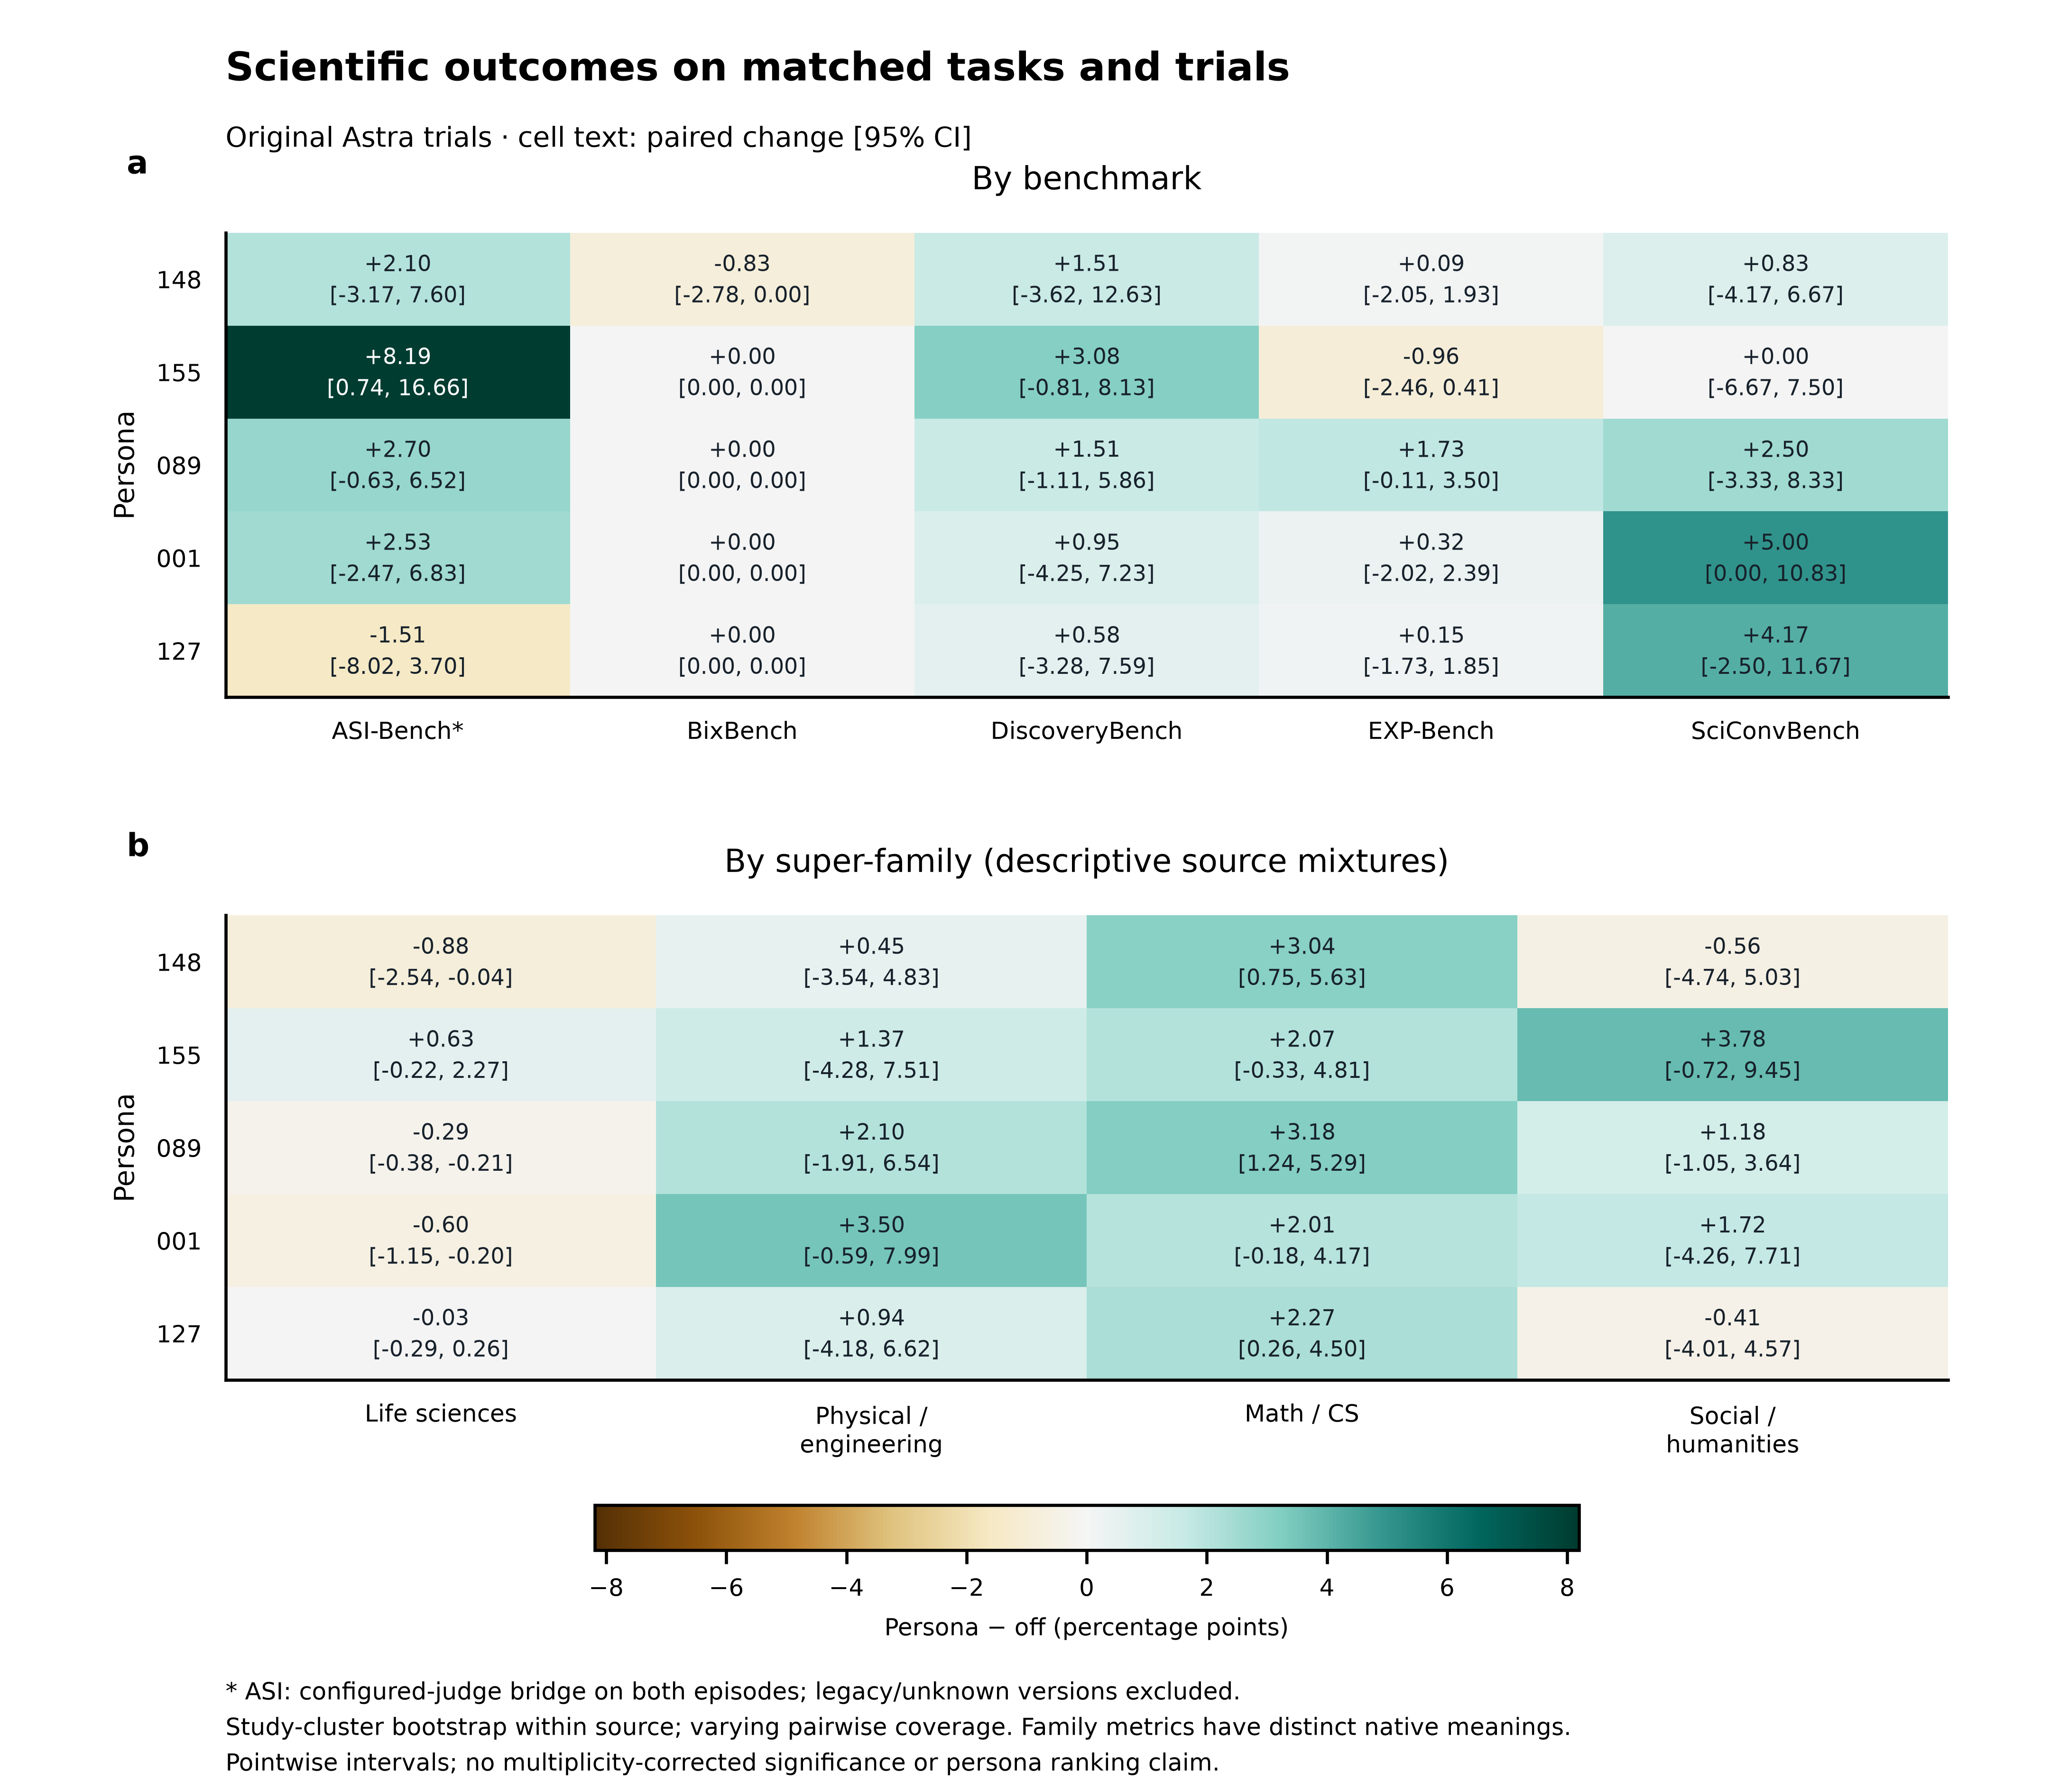

In [7]:
display(Image(filename=str(analysis.BASE/'figures/consolidated/matched_performance.png'),width=1000))

## Limits and report
At least one trial job must be complete; individual episodes can still be unscored. Unequal trial counts, technical missingness, conditional repairs and persona selection limit inference. Fewer than two studies yields an unavailable CI; singleton source-by-family strata cannot contribute estimable between-study variation. The full report is `ALL_AVAILABLE_PERFORMANCE.md`; its original-only sensitivity retains pre-repair evidence. No new API calls.

## Selected five settings: all-pairs performance changes
Settings: off/155/001/003/046. Left: available performance and pointwise 95% CIs. Right: nine full pairwise matrices, one per benchmark or super-family. Cell = row minus column, computed on compatible task–trial matches; trials average within task, then tasks receive equal weight. Colors encode two-sided study-cluster sign-flip tests, Holm-corrected across all 90 unique comparisons. All observations in each source-study block flip together. Exact enumeration for at most 16 clusters; otherwise 99,999 draws, plus-one p values. Independent study blocks and joint sign symmetry or valid blockwise label exchangeability are required. Tests with fewer than two clusters are unavailable, retained as p=1 in the correction family. Diagonals are gray and untested. Mirrored cells are the same test. Green: positive significant; orange: negative significant; light gray: not significant; white: test unavailable. Gray is not equivalence. Pairwise task counts differ; a matrix is not a transitive ranking.
This is exploratory because personas were selected using observed results. Inference conditions on available trials; repairs replace outcomes, not additional trials. Super-family scores mix native metrics. Available ASI scores mix evaluator versions; paired ASI comparisons require corrected judges. Full p values and coverage: `data/pairwise_selected/comparisons.csv`.

```json
{
  "statistic": "Row minus column; match task and trial, average trials within task, then tasks equally.",
  "test": "Two-sided study-cluster sign flip: all questions/trials in each source-study block change sign together; exact if <=16 clusters, otherwise 99999 random flips with plus-one correction.",
  "assumptions": "Independent study blocks and joint sign symmetry under null (or valid blockwise label exchangeability); not a distribution-free test of only a zero mean.",
  "multiplicity": "Holm over all 90 unique persona-pair \u00d7 group comparisons; mirrored cells are not additional tests; unavailable tests count as p=1.",
  "scope": "Exploratory, outcome-selected personas, conditional on observed trials and evaluable compatible pairs. Sparse clusters yield coarse p values; no test for <2 clusters. Missing scientific submissions score zero; infrastructure failures excluded. Source-study blocks preserved; families are descriptive mixtures.",
  "snapshot_sha256": "32653a253228c0a71f10f7b691c985fd7d9e36aadcc05880bce5769e6ce3569f",
  "seed": 20261001
}
```

Unique tests: 90 Holm significant: 0


"""Absolute score heatmaps plus nine categorical-significance pairwise matrices."""
import json
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap,BoundaryNorm
from matplotlib.patches import Patch
from plot_all_available import BASE,FIG,SOURCES,FAMILIES,NAMES,label,write_csv,require_matplotlib_panel_alignment
from pairwise_performance import ARMS,DEST

def main(dest=DEST, fig_dir=FIG, test_label="Study-cluster sign flip"):
    FIG=fig_dir
    FIG.mkdir(parents=True,exist_ok=True);(FIG/"qa").mkdir(exist_ok=True)
    s=json.loads((BASE/'data/all_available/summary.json').read_text());pairs=json.loads((dest/'summary.json').read_text())
    plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['DejaVu Sans'],'font.size':7,'xtick.labelsize':6,'ytick.labelsize':6,'pdf.fonttype':42,'svg.fonttype':'none'})
    fig=plt.figure(figsize=(310/25.4,215/25.4))
    left=fig.add_gridspec(2,1,left=.06,right=.355,bottom=.22,top=.88,hspace=.32)
    right=fig.add_gridspec(3,3,left=.435,right=.98,bottom=.19,top=.88,wspace=.38,hspace=.47)
    la=[];ra=[];data=[]
    for row,(field,groups) in enumerate([('source',SOURCES),('family',FAMILIES)]):
        ax=fig.add_subplot(left[row]);la.append(ax)
        values=np.array([[s['absolute']['available'][a][field][g]['mean'] for g in groups] for a in ARMS],float)
        im=ax.imshow(values,cmap='Blues',vmin=0,vmax=100,aspect='auto')
        ax.set_yticks(range(5),[f"{label(a)} · {len(s['coverage'][a]['trials_with_scores'])}T" for a in ARMS])
        ax.set_xticks(range(len(groups)),[NAMES[g].replace('Physical / engineering','Physical /\nengineering').replace('Social / humanities','Social /\nhumanities') for g in groups]);ax.tick_params(length=0)
        ax.set_title('By benchmark' if row==0 else 'By super-family',fontsize=8,pad=8)
        for y,a in enumerate(ARMS):
            for x,g in enumerate(groups):
                z=s['absolute']['available'][a][field][g];m=z['mean'];ci=z['ci95']
                txt='No data' if m is None else f'{m:.2f}\n'+(f'[{ci[0]:.2f}, {ci[1]:.2f}]' if ci else 'CI unavailable')
                ax.text(x,y,txt,ha='center',va='center',fontsize=5.5,color='white' if m is not None and m>65 else '#17212B')
        for spine in ax.spines.values():spine.set_visible(False)
    colors=['#D98E4B','#EEEEEE','#58AA85','#D0D0D0','#FFFFFF']
    cmap=ListedColormap(colors);norm=BoundaryNorm(np.arange(-.5,5,.999999),5)
    groups=[('source',g) for g in SOURCES]+[('family',g) for g in FAMILIES]
    for k,(field,g) in enumerate(groups):
        ax=fig.add_subplot(right[k//3,k%3]);ra.append(ax);classes=np.full((5,5),3.);texts={}
        for r in pairs['comparisons']:
            if r['level']!=field or r['group']!=g:continue
            i=ARMS.index(r['persona_i']);j=ARMS.index(r['persona_j'])
            for y,x,sign in [(i,j,1),(j,i,-1)]:
                m=None if r['mean'] is None else r['mean']*sign;p=r['p_holm']
                classes[y,x]=4 if m is None or p is None else (2 if m>0 else 0) if p<.05 else 1
                texts[y,x]='NA' if m is None else ('0.00' if abs(m)<.005 else f'{m:+.2f}')
                data.append(dict(r,row_persona=ARMS[y],column_persona=ARMS[x],display_difference=m,category=['negative significant','not significant','positive significant','diagonal','unavailable test'][int(classes[y,x])]))
        ax.imshow(classes,cmap=cmap,norm=norm,aspect='auto',interpolation='nearest')
        for (y,x),txt in texts.items():ax.text(x,y,txt,ha='center',va='center',fontsize=6)
        ax.set_xticks(range(5),[label(a) for a in ARMS]);ax.set_yticks(range(5),[label(a) for a in ARMS]);ax.tick_params(length=0,pad=3)
        title=NAMES[g].replace('Physical / engineering','Physical / engineering').replace('Social / humanities','Social / humanities')
        ax.set_title(title,fontsize=7,pad=7)
        for spine in ax.spines.values():spine.set_visible(False)
    fig.text(.2075,.962,'A  Avail

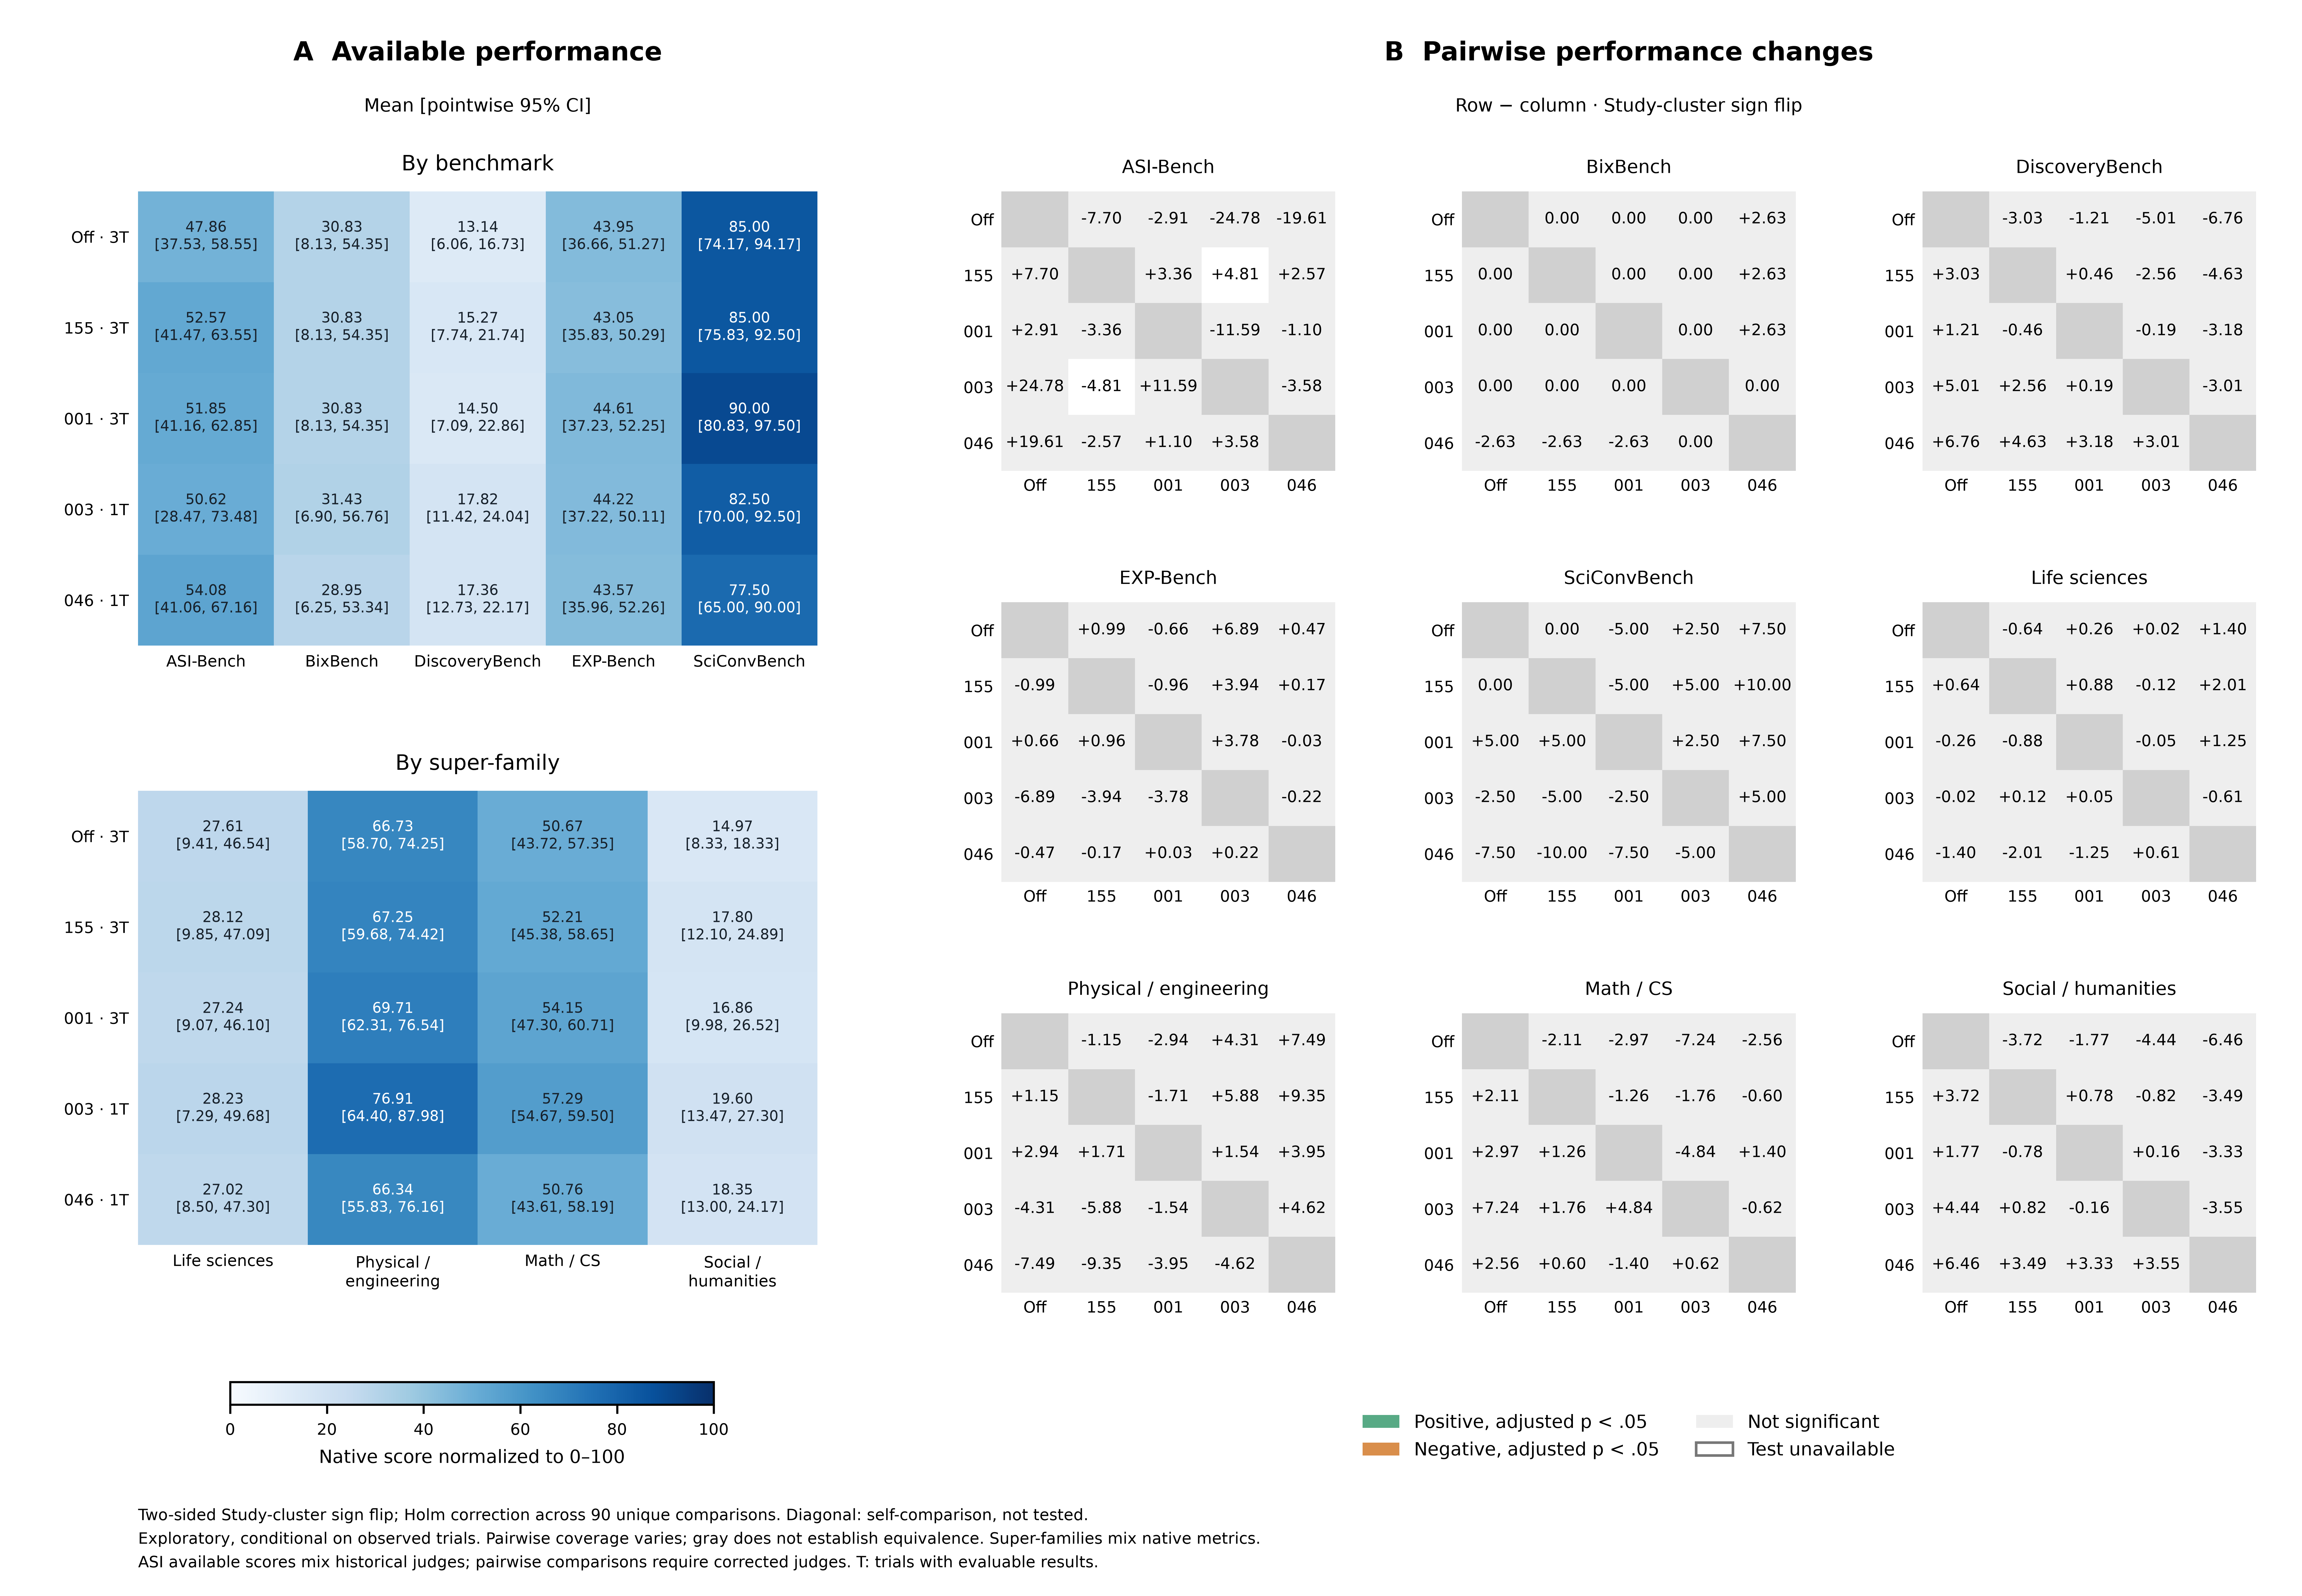

In [8]:
RECOMPUTE_PAIRWISE=False
if RECOMPUTE_PAIRWISE or not (pairwise_performance.DEST/'summary.json').exists(): pairwise_performance.main()
pairwise=json.loads((pairwise_performance.DEST/'summary.json').read_text())
display(Markdown('```json\n'+json.dumps(pairwise['methods'],indent=2)+'\n```'))
print('Unique tests:',len(pairwise['comparisons']),'Holm significant:',sum(r['p_holm'] is not None and r['p_holm']<.05 for r in pairwise['comparisons']))
display(Code(Path(plotting.__file__).read_text(),language='python'))
plotting.main()
display(Image(filename=str(plotting.FIG/'pairwise_performance.png'),width=1600))


## Statistical sensitivity: fixed three-method comparison
The same 90 mean-difference hypotheses, matched data, two-sided alternatives, and within-method Holm correction are retained. Compare unstudentized study-cluster sign flips, CR1 cluster-robust t tests, and studentized study-cluster sign flips. These methods are not interchangeable guarantees: sign flips require joint block symmetry/exchangeability; CR1 t inference is approximate and can be unreliable with few or highly unequal clusters. These are exploratory sensitivity outputs; selecting a method after inspecting significance does not provide selection-adjusted evidence. Unavailable tests retain p=1 in the correction family. Earlier primary figures are preserved.
References: [paired permutation tests](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html), [cluster-robust covariance](https://www.statsmodels.org/v0.14.1/generated/statsmodels.stats.sandwich_covariance.cov_cluster.html), [cluster t inference](https://www.statsmodels.org/dev/generated/statsmodels.regression.linear_model.OLSResults.get_robustcov_results.html).

| Method | Raw p < .05 | Holm p < .05 | Unavailable |
|---|---|---|---|
| Study-cluster sign flip | 1 | 0 | 1 |
| Cluster-robust t (CR1) | 1 | 0 | 1 |
| Studentized cluster sign flip | 1 | 0 | 1 |

### Study-cluster sign flip

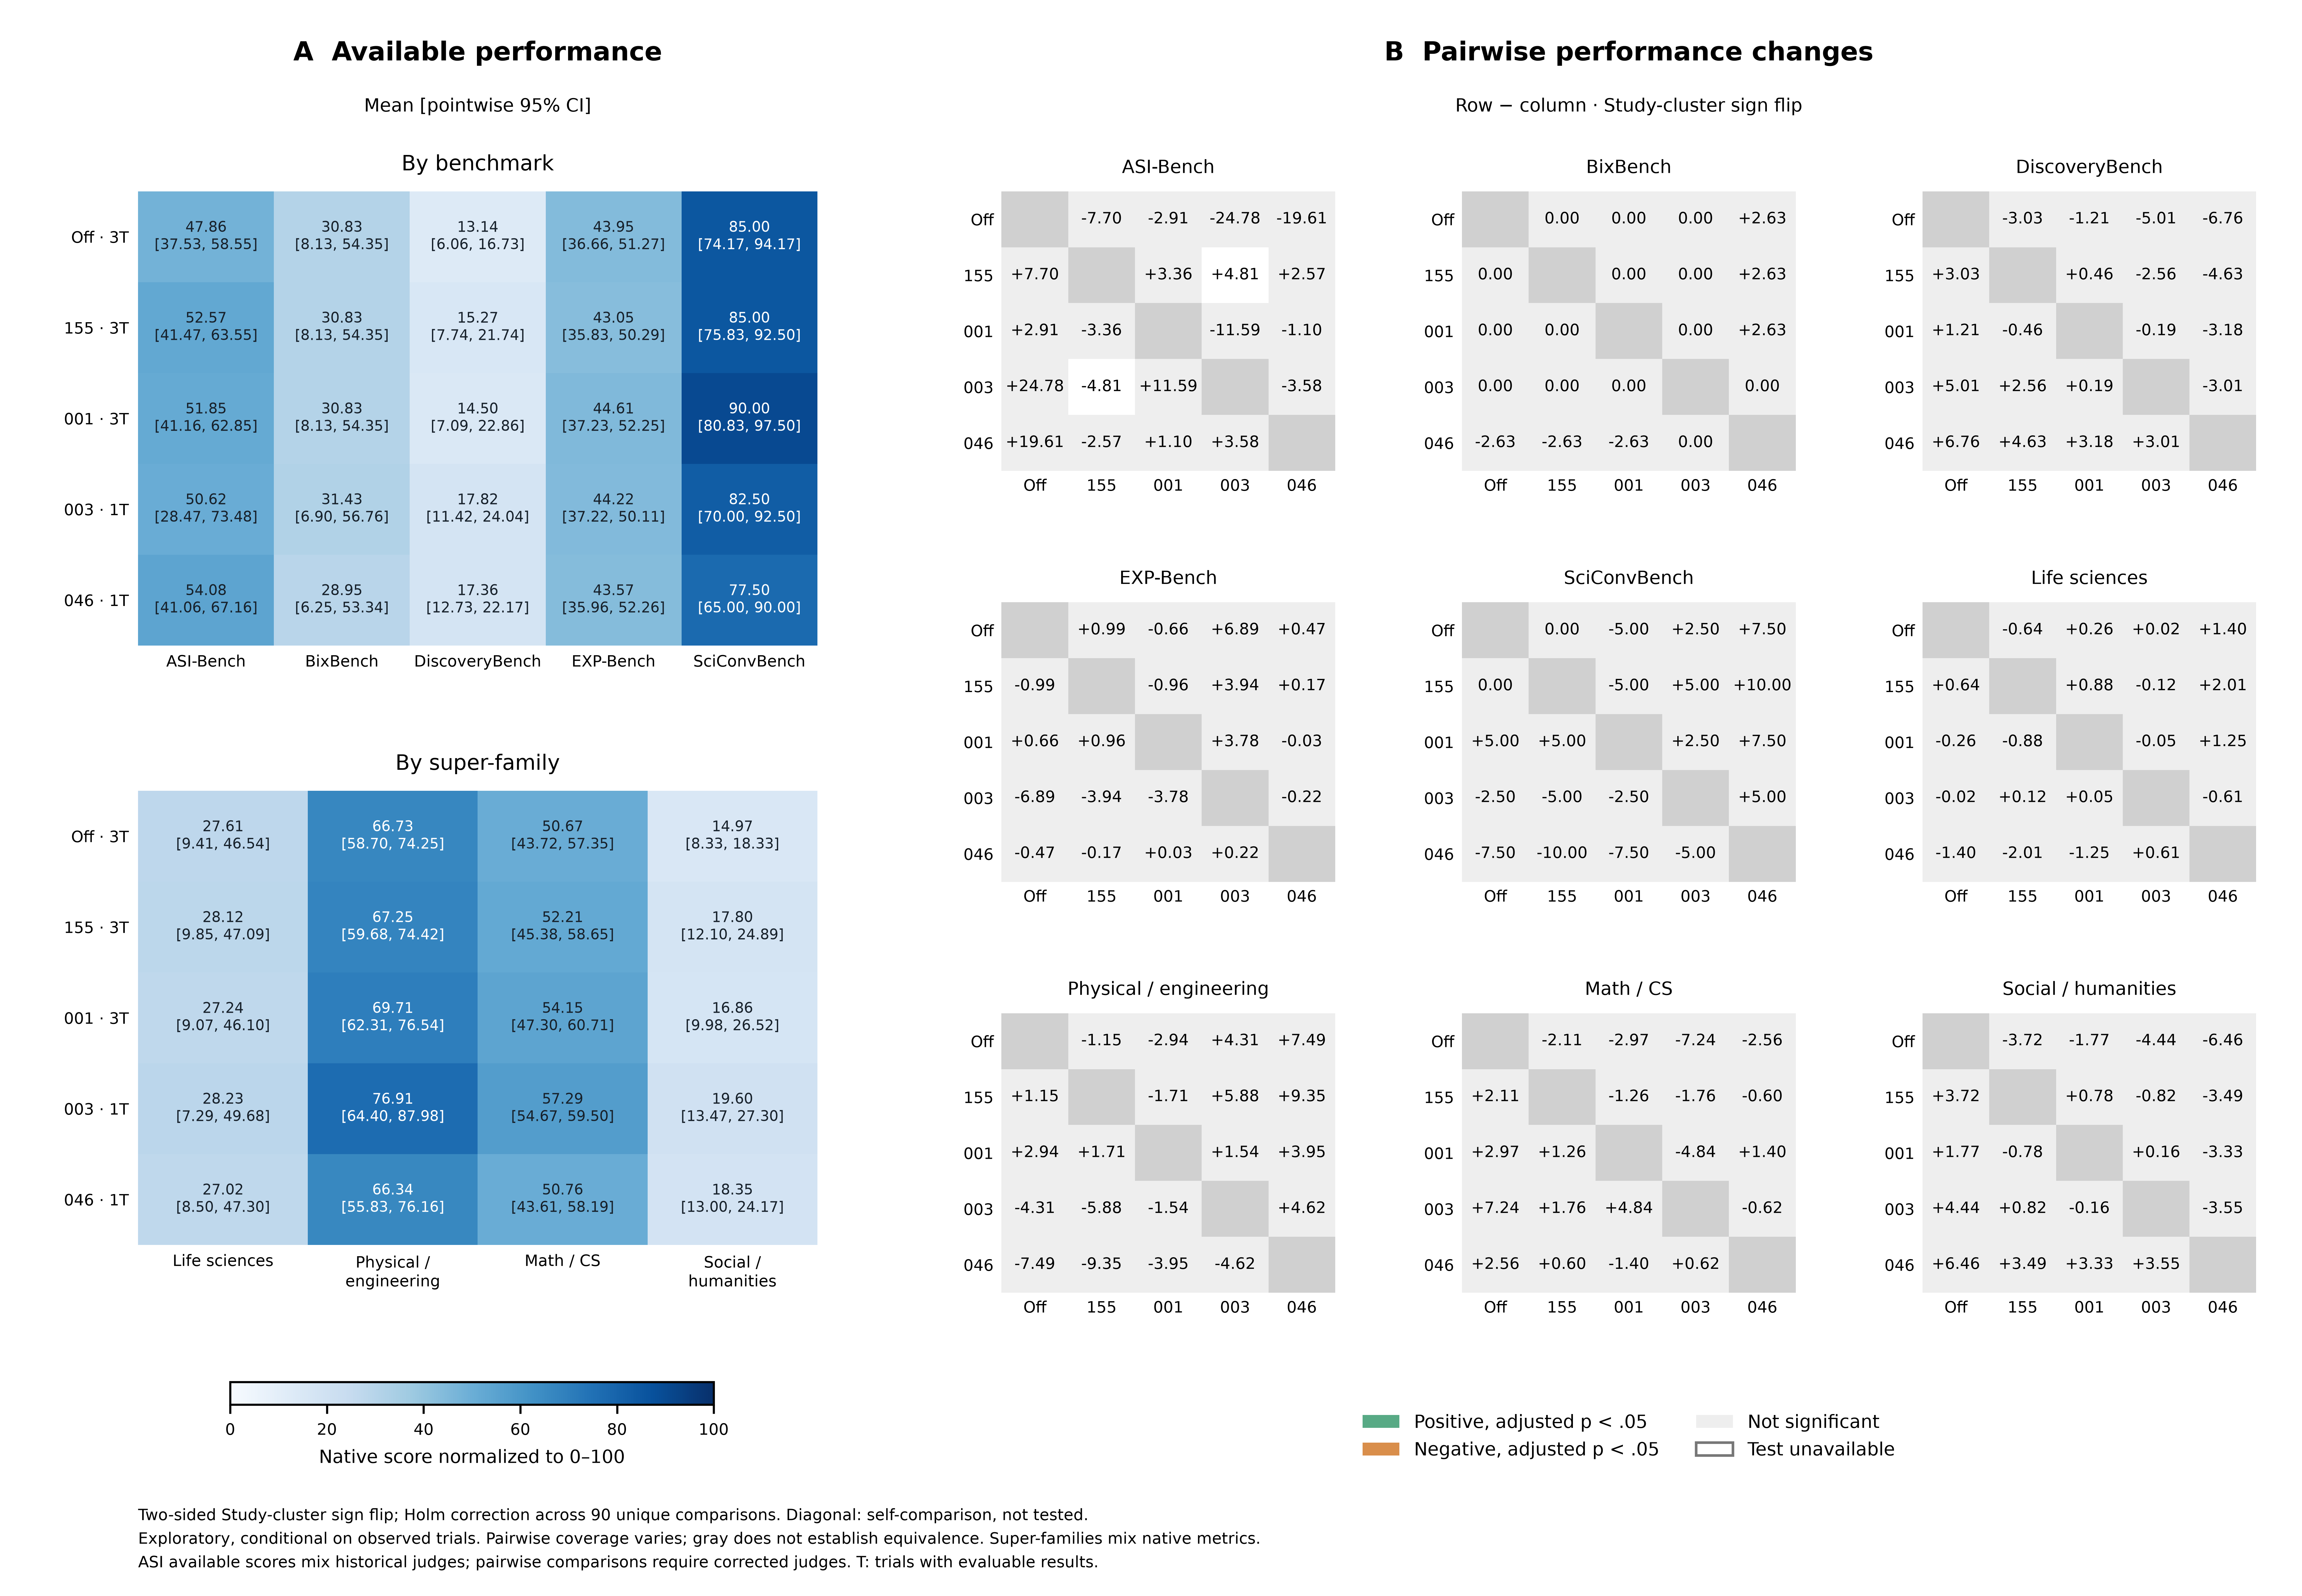

### Cluster-robust t (CR1)

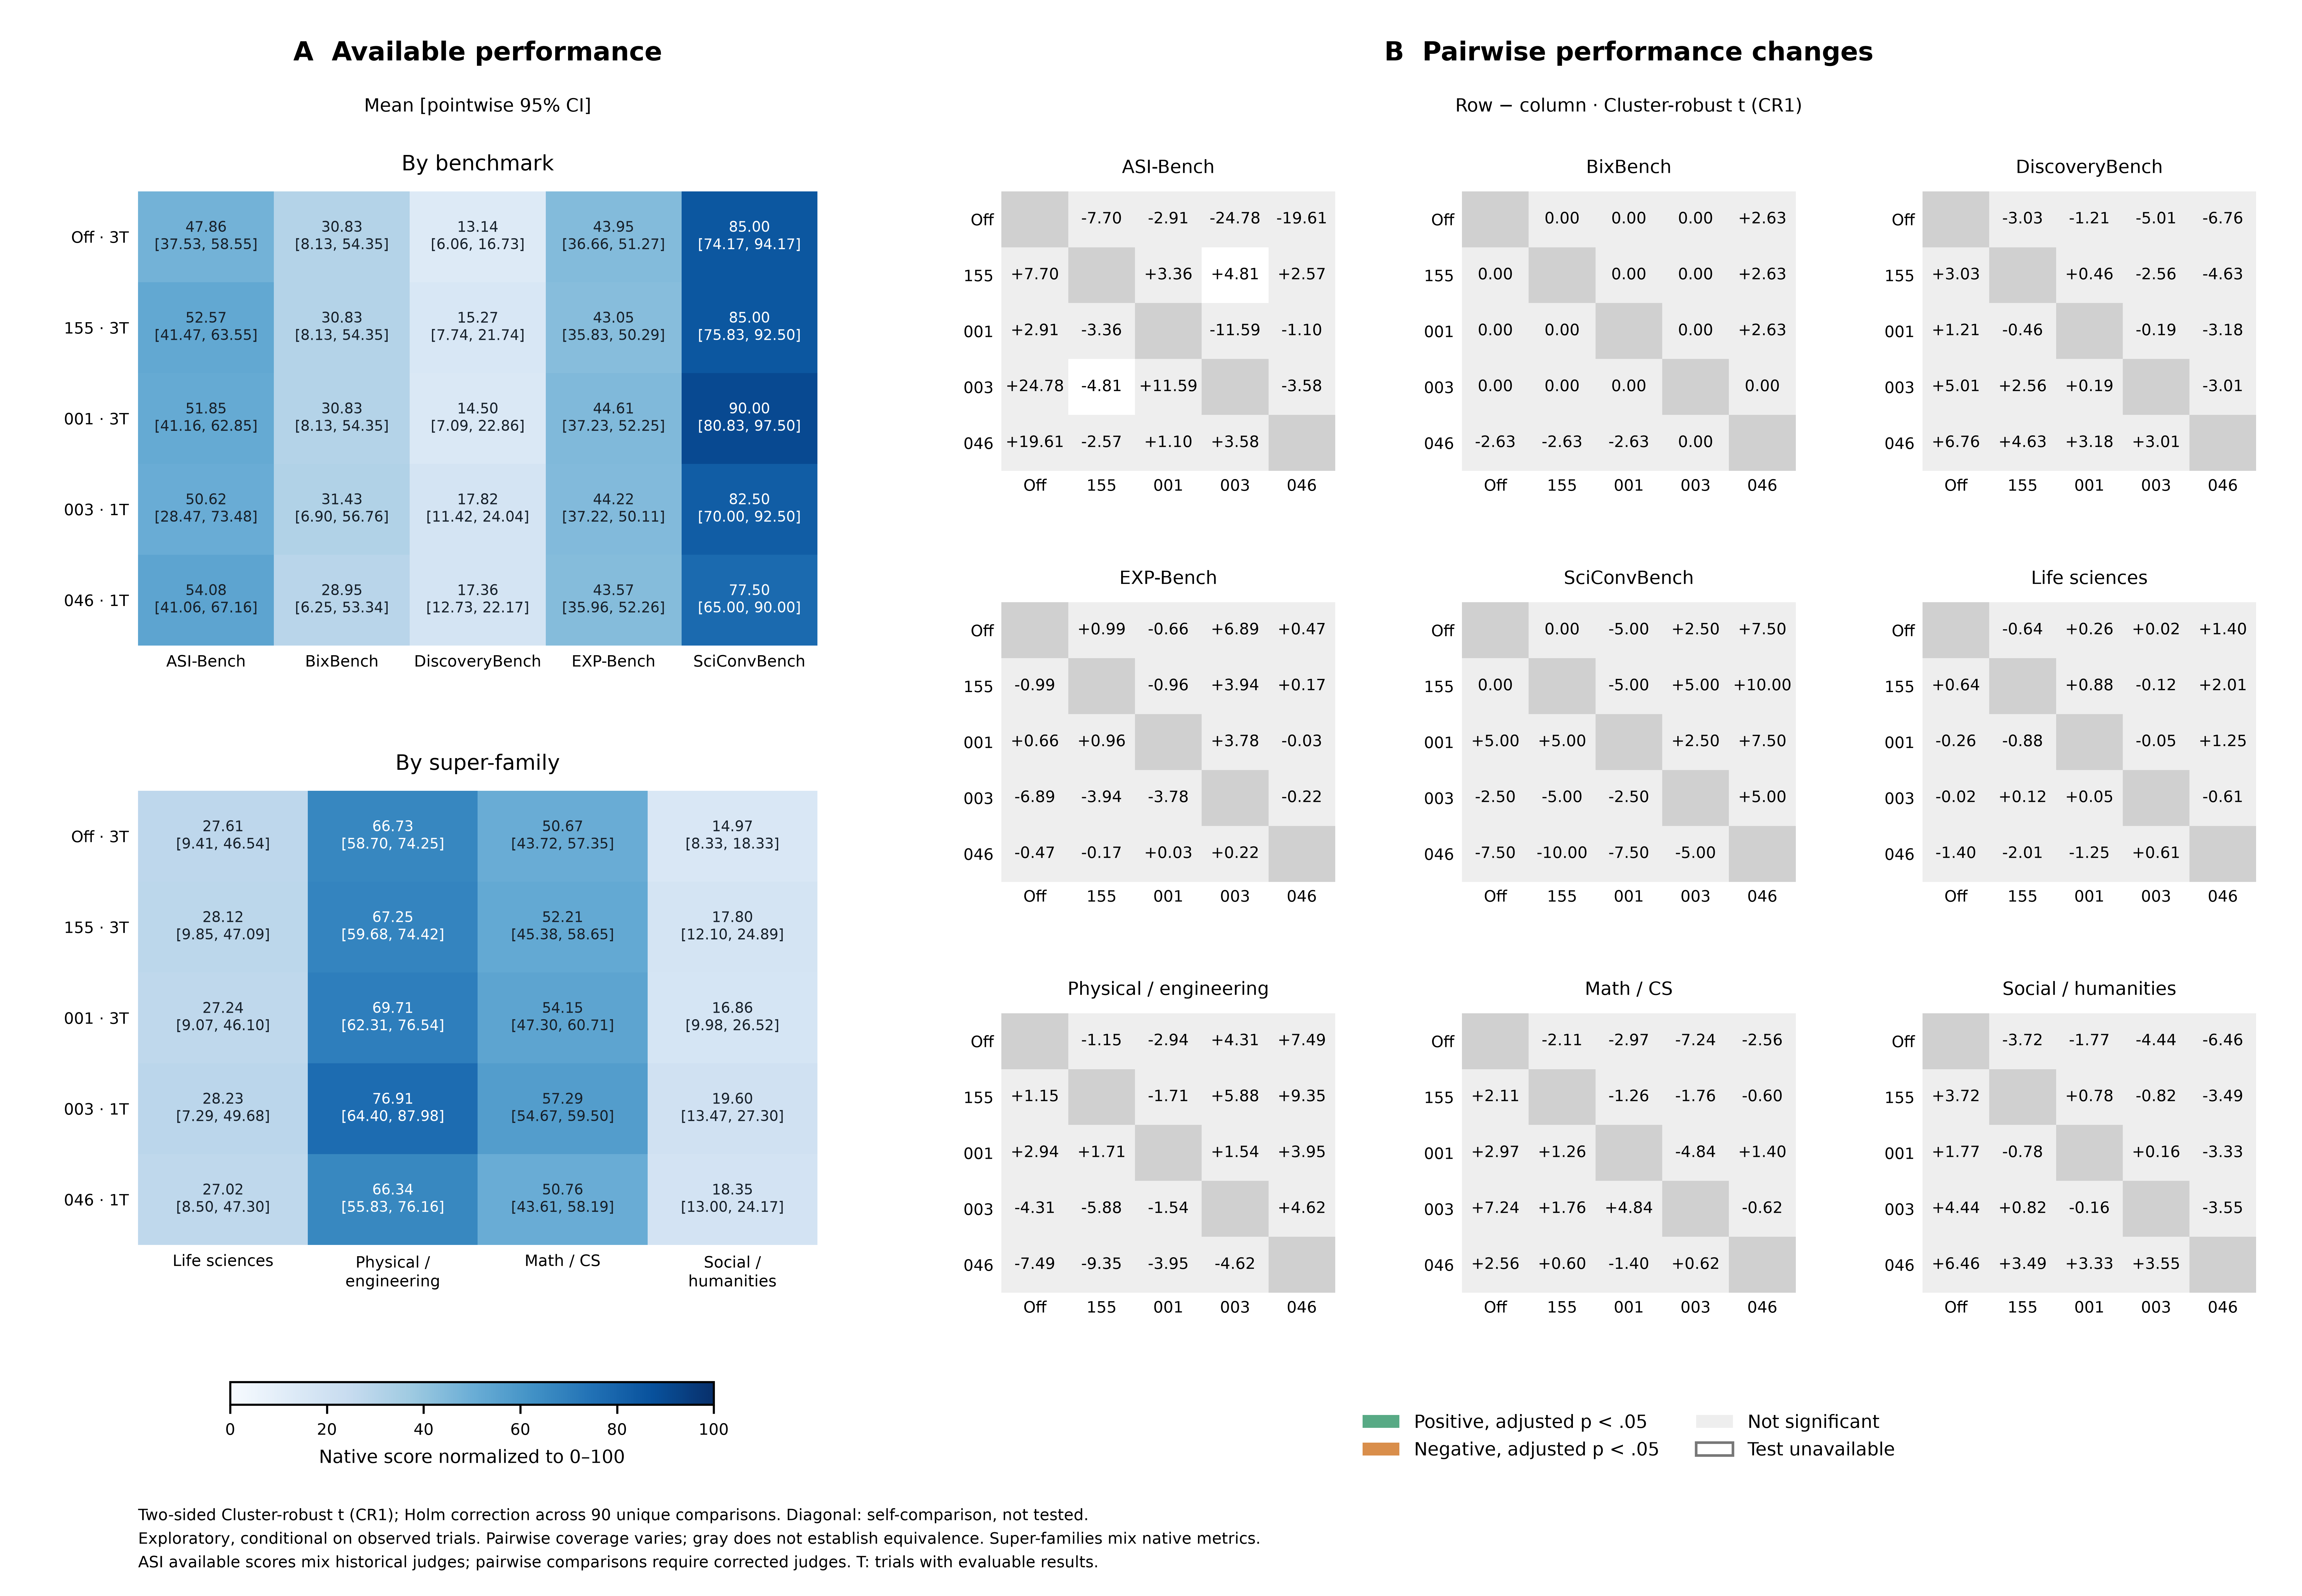

### Studentized cluster sign flip

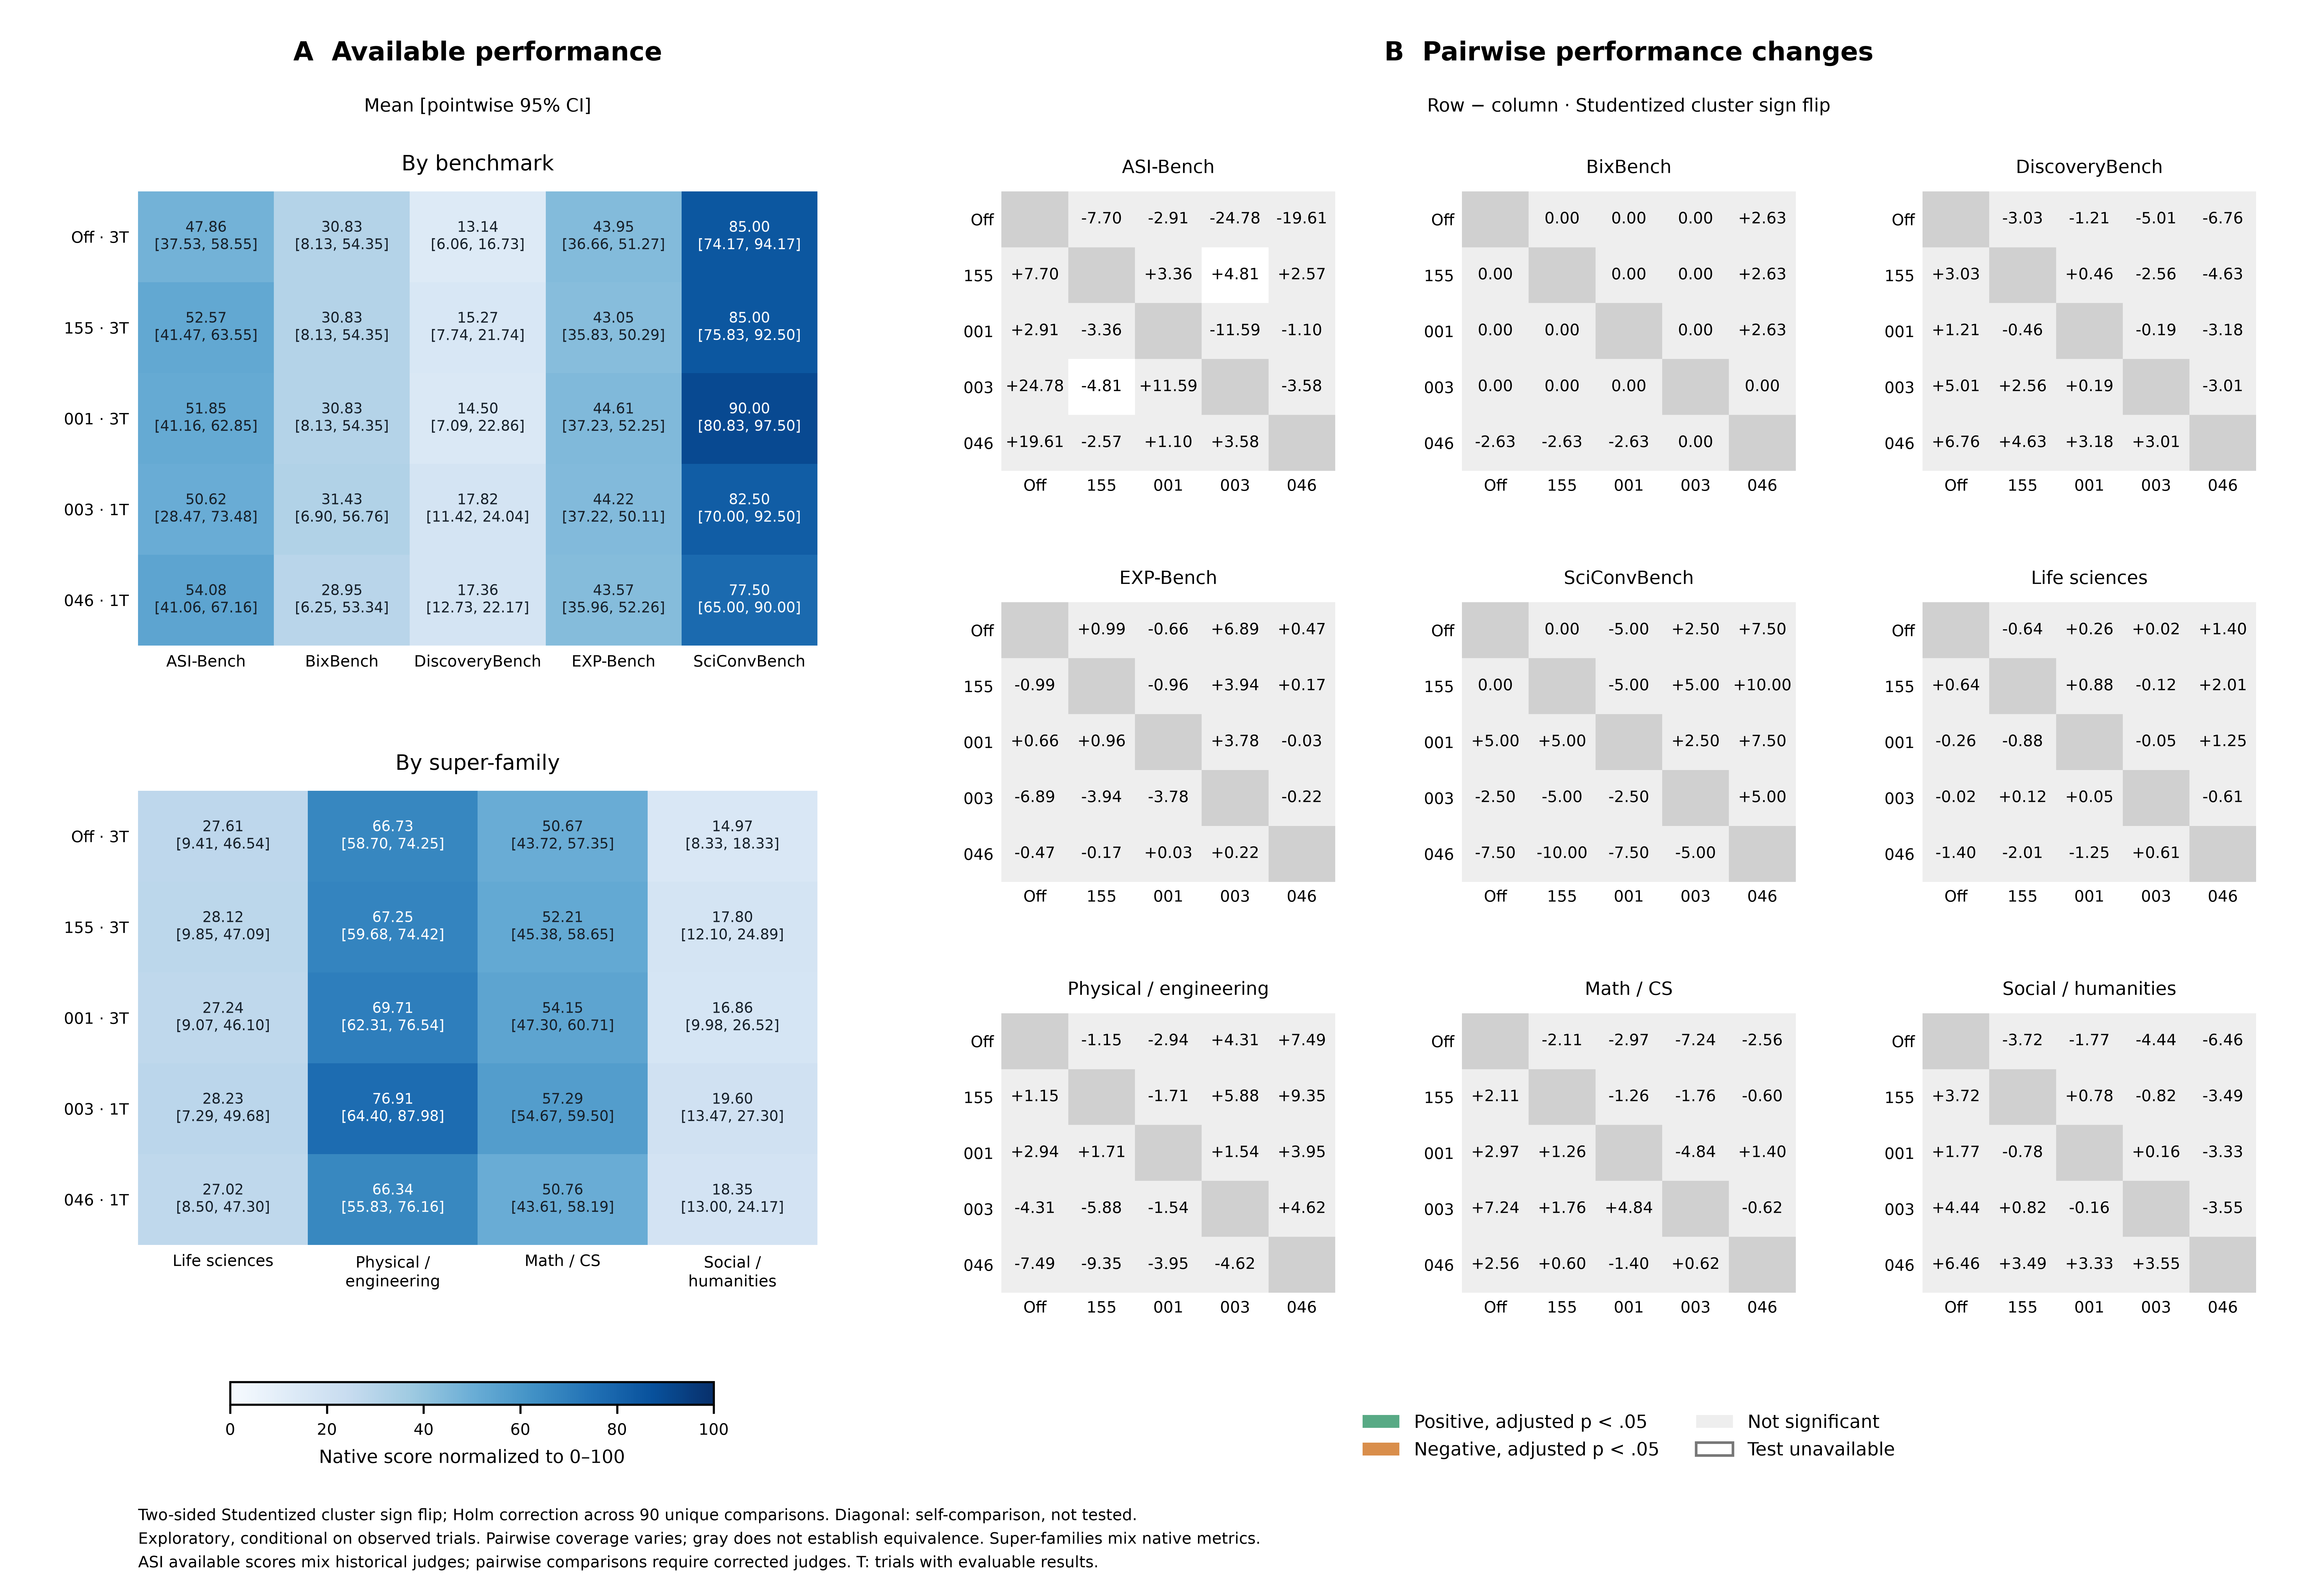

In [9]:
import performance_test_sensitivity as sensitivity
overview=json.loads((sensitivity.OUT/'overview.json').read_text())
display(Markdown(markdown_table(['Method','Raw p < .05','Holm p < .05','Unavailable'],[[r['label'],r['raw_p_below_05'],r['holm_below_05'],r['unavailable']] for r in overview])))
for method,title in sensitivity.METHODS.items():
    folder=analysis.BASE/'figures/test_sensitivity'/method
    plotting.main(dest=sensitivity.OUT/method,fig_dir=folder,test_label=title)
    display(Markdown('### '+title))
    display(Image(filename=str(folder/'pairwise_performance.png'),width=1600))
